CROP DISEASE DETECTION

In [1]:
# 1. CONFIGURATION

import os
import zipfile
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import MobileNetV2

def preprocess_input(x):
    x = tf.cast(x, tf.float32)
    return (x / 127.5) - 1.0

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [3]:
# 2. EXTRACT DATASET

ZIP_FILE = "/content/archive (3).zip"

EXTRACT_DIR = "/content/tomato_dataset"
DATASET_DIR = "/content/tomato_split"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

EPOCHS_INITIAL = 15
EPOCHS_FINE_TUNE = 10

SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEAT_RATIO = 0.15

MODEL_PATH = "/content/tomato_leaf_disease_model.keras"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# 3. CHECK DATASET

if os.path.exists(EXTRACT_DIR):
  shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_FILE, "r") as zip_ref:
  zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [5]:
# 4. DATASET STRUCTURE
def find_class_directories(root):
  class_dirs = []

  for item in Path(root).iterdir():
    if item.is_dir():
      images = list(item.glob("*.jpg"))
      images += list(item.glob("*.jpeg"))
      images += list(item.glob("*.png"))

      if len(images) > 0:
        class_dirs.append(item)

  return class_dirs


class_dirs = find_class_directories(EXTRACT_DIR)

print("\nclasses found:")
for folder in class_dirs:
  print(" -", folder.name)

print("\nNumber of classes;", len(class_dirs))


classes found:

Number of classes; 0


In [7]:
# 6. PREPARE DATASET

import os
import shutil

# Remove the empty split created earlier
if os.path.exists(DATASET_DIR):
    shutil.rmtree(DATASET_DIR)

# Copy the existing dataset split
shutil.copytree(EXTRACT_DIR, DATASET_DIR)

print("Existing dataset split copied successfully!")

print("\nTrain contents:")
print(os.listdir(os.path.join(DATASET_DIR, "train")))

print("\nValidation contents:")
print(os.listdir(os.path.join(DATASET_DIR, "valid")))

print("\nTest contents:")
print(os.listdir(os.path.join(DATASET_DIR, "test")))

Existing dataset split copied successfully!

Train contents:
['labels', 'images']

Validation contents:
['labels', 'images']

Test contents:
['labels', 'images']


In [8]:
# 7. LOAD TOMATO DATASET

import os
import tensorflow as tf

TRAIN_DIR = "/content/tomato_split/train/images"
VALID_DIR = "/content/tomato_split/valid/images"
TEST_DIR = "/content/tomato_split/test/images"

# Supported image formats
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

train_images = [
    os.path.join(TRAIN_DIR, f)
    for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

valid_images = [
    os.path.join(VALID_DIR, f)
    for f in os.listdir(VALID_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

test_images = [
    os.path.join(TEST_DIR, f)
    for f in os.listdir(TEST_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

print("Training images:", len(train_images))
print("Validation images:", len(valid_images))
print("Test images:", len(test_images))

Training images: 645
Validation images: 61
Test images: 31


In [9]:
# 8. CLASS NAMES

class_names = [
    "Bacterial Spot",
    "Early Blight",
    "Healthy",
    "Late Blight",
    "Leaf Mold",
    "Target Spot",
    "Black Spot"
]

print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Target Spot', 'Black Spot']
Number of classes: 7


In [10]:
# CREATE IMAGE PATHS AND LABELS

import os

def create_dataset(image_dir, label_dir):
    images = []
    labels = []

    image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

    for filename in os.listdir(image_dir):

        if not filename.lower().endswith(image_extensions):
            continue

        image_path = os.path.join(image_dir, filename)

        base_name = os.path.splitext(filename)[0]
        label_file = os.path.join(label_dir, base_name + ".txt")

        if not os.path.exists(label_file):
            continue

        with open(label_file, "r") as f:
            line = f.readline().strip()

        if line:
            class_id = int(line.split()[0])
            images.append(image_path)
            labels.append(class_id)

    return images, labels


train_images, train_labels = create_dataset(
    "/content/tomato_split/train/images",
    "/content/tomato_split/train/labels"
)

validation_images, validation_labels = create_dataset(
    "/content/tomato_split/valid/images",
    "/content/tomato_split/valid/labels"
)

test_images, test_labels = create_dataset(
    "/content/tomato_split/test/images",
    "/content/tomato_split/test/labels"
)

print("Training:", len(train_images))
print("Validation:", len(validation_images))
print("Test:", len(test_images))

Training: 627
Validation: 59
Test: 31


In [11]:
# REBUILD DATASETS

import tensorflow as tf

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0

    return image, tf.cast(label, tf.int32)


train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_images, train_labels)
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (validation_images, validation_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_images, test_labels)
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.batch(BATCH_SIZE)
validation_dataset = validation_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

print("Datasets created successfully!")

Datasets created successfully!


In [12]:
# 9. IMPROVE DATA PIPELINE PERFORMANCE

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

print("Data pipeline performance improved!")

Data pipeline performance improved!


In [13]:
# 10. DATA AUGMENTATION

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

print("Data augmentation created!")

Data augmentation created!


In [14]:
# RESET AND REBUILD MODEL

import tensorflow as tf

tf.keras.backend.clear_session()

print("TensorFlow:", tf.__version__)
print("Keras:", tf.keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


In [16]:
# 11. LOAD MOBILENETV2 FRESH

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded!")
print("Input:", base_model.input_shape)
print("Output:", base_model.output_shape)

MobileNetV2 loaded!
Input: (None, 224, 224, 3)
Output: (None, 7, 7, 1280)


In [17]:
# 12. BUILD MODEL

inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="image_input"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(
    7,
    activation="softmax",
    name="predictions"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs
)

# IMPORTANT: build the complete model BEFORE model.fit()
dummy_input = tf.zeros((1, 224, 224, 3))
dummy_output = model(dummy_input, training=False)

print("Model built successfully!")
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

Model built successfully!
Model input: (None, 224, 224, 3)
Model output: (None, 7)


In [19]:
# 13. COMPILE MODEL

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    run_eagerly=True
)

print("Model compiled successfully!")

Model compiled successfully!


In [20]:
# 14. CALLBACKS

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

print("Callbacks created successfully!")

Callbacks created successfully!


In [21]:
# REBUILD MODEL CLEANLY

import tensorflow as tf
import gc

# Clear old Keras models
tf.keras.backend.clear_session()
gc.collect()

# Create a completely fresh MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# Create a completely fresh model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(7, activation="softmax")
], name="tomato_leaf_classifier")

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh model created and compiled!")
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

Fresh model created and compiled!
Model input: (None, 224, 224, 3)
Model output: (None, 7)


In [22]:
# FIX DATASET BATCHING

train_dataset = train_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
).prefetch(tf.data.AUTOTUNE)

validation_dataset = validation_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
).prefetch(tf.data.AUTOTUNE)

test_dataset = test_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
).prefetch(tf.data.AUTOTUNE)

print("Datasets batched successfully!")

Datasets batched successfully!


In [23]:
# FIX DATASET - BATCH ONLY ONCE

import tensorflow as tf

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    # MobileNetV2 preprocessing
    image = (image / 127.5) - 1.0

    return image, tf.cast(label, tf.int32)


# Create completely fresh datasets
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_images, train_labels)
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (validation_images, validation_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_images, test_labels)
)


# Load and preprocess images
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)


# IMPORTANT: BATCH ONLY ONCE
train_dataset = train_dataset.batch(BATCH_SIZE)
validation_dataset = validation_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)


# Prefetch only
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


print("Datasets rebuilt correctly!")
print("Dataset structure:", train_dataset.element_spec)

Datasets rebuilt correctly!
Dataset structure: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [25]:
# CHECK DATASET AND MODEL

images, labels = next(iter(train_dataset))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

output = model(images, training=False)

print("Model output shape:", output.shape)
print("Model and dataset are compatible!")

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Model output shape: (32, 7)
Model and dataset are compatible!


In [24]:
# 15. INITIAL TRAINING

history_initial = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_INITIAL,
    callbacks=callbacks
)

print("Initial training completed!")

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.2392 - loss: 2.0438 - val_accuracy: 0.3898 - val_loss: 1.7587 - learning_rate: 1.0000e-04
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.3907 - loss: 1.6447 - val_accuracy: 0.3898 - val_loss: 1.5335 - learning_rate: 1.0000e-04
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.4242 - loss: 1.5312 - val_accuracy: 0.4068 - val_loss: 1.4317 - learning_rate: 1.0000e-04
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.4466 - loss: 1.4278 - val_accuracy: 0.3729 - val_loss: 1.3730 - learning_rate: 1.0000e-04
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.4817 - loss: 1.3673 - val_accuracy: 0.4237 - val_loss: 1.3331 - learning_rate: 1.0000e-04
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.5120 - loss: 1.3043 - val_accuracy: 0.4407 - val_loss: 1.2975 - learning_rate: 1.0000e-04
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.5279 - loss:

In [28]:
# 16. FINE-TUNING

base_model.trainable = True

# Freeze the first 100 layers
for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks
)

print("Fine-tuning completed!")

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.8230 - loss: 0.5950 - val_accuracy: 0.7458 - val_loss: 0.9697 - learning_rate: 1.0000e-05
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.9107 - loss: 0.4194 - val_accuracy: 0.7458 - val_loss: 0.9479 - learning_rate: 1.0000e-05
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.9362 - loss: 0.3309 - val_accuracy: 0.7458 - val_loss: 0.9256 - learning_rate: 1.0000e-05
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.9585 - loss: 0.2591 - val_accuracy: 0.7458 - val_loss: 0.9037 - learning_rate: 1.0000e-05
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.9697 - loss: 0.2129 - val_accuracy: 0.7458 - val_loss: 0.8853 - learning_rate: 1.0000e-05
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.9872 - loss: 0.1761 - val_accuracy: 0.7458 - val_loss: 0.8681 - learning_rate: 1.0000e-05
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.9920 - loss:

In [29]:
# 17. EVALUATE MODEL

test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.7419 - loss: 0.7374
Test Loss: 0.737428605556488
Test Accuracy: 0.7419354915618896
Test Accuracy: 74.19%


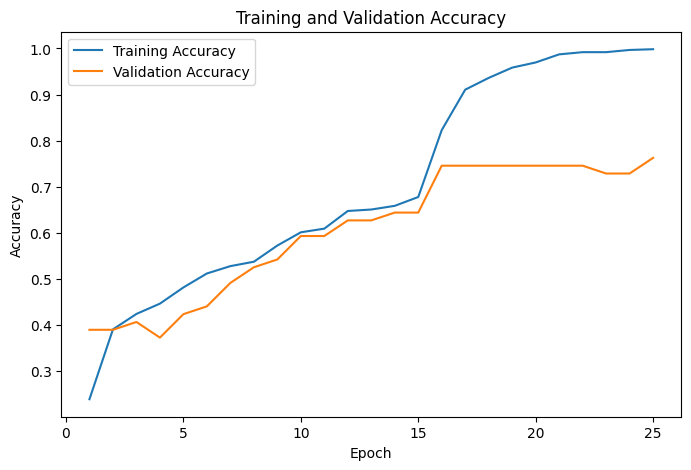

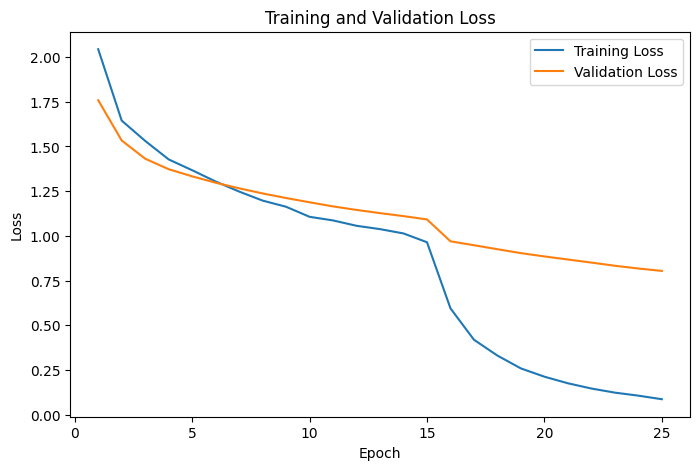

In [30]:
# 18. PLOT TRAINING HISTORY

import matplotlib.pyplot as plt

# Combine initial training and fine-tuning history
initial_acc = history_initial.history["accuracy"]
initial_val_acc = history_initial.history["val_accuracy"]
initial_loss = history_initial.history["loss"]
initial_val_loss = history_initial.history["val_loss"]

fine_acc = history_fine.history["accuracy"]
fine_val_acc = history_fine.history["val_accuracy"]
fine_loss = history_fine.history["loss"]
fine_val_loss = history_fine.history["val_loss"]

accuracy = initial_acc + fine_acc
val_accuracy = initial_val_acc + fine_val_acc

loss = initial_loss + fine_loss
val_loss = initial_val_loss + fine_val_loss

epochs = range(1, len(accuracy) + 1)

# Accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, accuracy, label="Training Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

# Loss plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

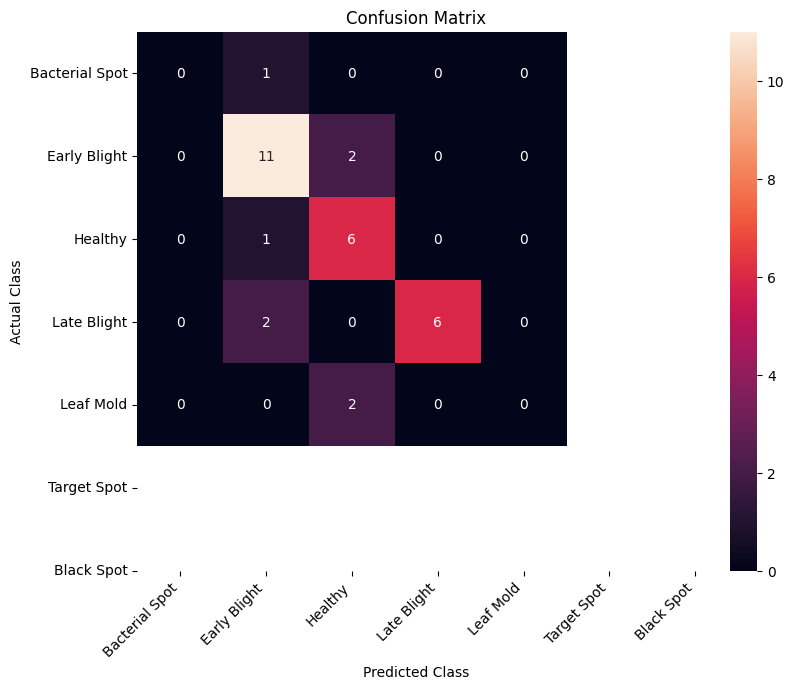

In [31]:
# 19. CONFUSION MATRIX

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt

In [32]:
# 20. CLASSIFICATION REPORT

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

                precision    recall  f1-score   support

Bacterial Spot       0.00      0.00      0.00         1
  Early Blight       0.73      0.85      0.79        13
       Healthy       0.60      0.86      0.71         7
   Late Blight       1.00      0.75      0.86         8
     Leaf Mold       0.00      0.00      0.00         0
   Target Spot       0.00      0.00      0.00         2
    Black Spot       0.00      0.00      0.00         0

      accuracy                           0.74        31
     macro avg       0.33      0.35      0.34        31
  weighted avg       0.70      0.74      0.71        31



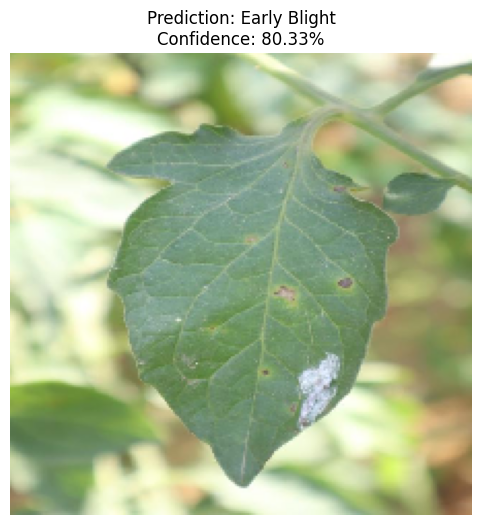

Test Image: IMG_0359_JPG.rf.e4fb9464647fd62372ad23e4e93acf58.jpg
Predicted Disease: Early Blight
Confidence: 80.33%


In [33]:
# 21. PREDICT A TEST IMAGE FROM DATASET

import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

TEST_IMAGE_DIR = "/content/tomato_split/test/images"

# Find images in the test folder
image_files = [
    f for f in os.listdir(TEST_IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Select the first test image
image_path = os.path.join(TEST_IMAGE_DIR, image_files[0])

# Load and resize image
image = load_img(
    image_path,
    target_size=IMG_SIZE
)

# Convert image to array
image_array = img_to_array(image)
image_array = np.expand_dims(image_array, axis=0)

# MobileNetV2 preprocessing
image_array = (image_array / 127.5) - 1.0

# Predict
prediction = model.predict(image_array, verbose=0)

predicted_class = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

# Display image and prediction
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Prediction: {class_names[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Test Image:", image_files[0])
print("Predicted Disease:", class_names[predicted_class])
print("Confidence: {:.2f}%".format(confidence))

In [34]:
# 22. SAVE FINAL MODEL

model.save(MODEL_PATH)

print("Final model saved successfully!")
print("Model location:", MODEL_PATH)

Final model saved successfully!
Model location: /content/tomato_leaf_disease_model.keras
